# 43008 Reinforcement Learning -- Assignment 3, Part E: Value-Based Deep Reinforcement Learning on Snake

**The Deadly Triad (project 48): Yue Liu (25211451), Jiahao Liu (14191136), Siqin Jin (26145324)**

**Project**: a controlled study of state representation, reward design and DQN stabilisation on a self-built Snake
environment (8 x 8 and 10 x 10 boards): tabular Q-learning; DQN on an 11-feature vector (observation A, MLP) or an
8-plane grid (observation B8, CNN); the discount factor; the replay buffer and the target network; Double DQN, Dueling
and prioritised replay; four reward designs (R0 sparse, R1 step penalty, R2 potential-based shaping, R3 naive distance
bonus) and a reward-hacking probe; random, BFS-greedy and Hamiltonian-cycle reference players. Every configuration is
trained with five seeds, the seed is the unit of replication and every interval is a 95 % Student-t interval over seeds.

**What this notebook does**: it regenerates every table and figure of the report from the training logs and shows them
in the report's order with the report's captions (Section 5), then checks every computed table against the report
source cell by cell (Section 6). `snake_rl.analysis.report` reads the run directories under `runs/` (per seed:
`config.yaml`, `metrics.csv`, `final_eval.json`) and writes the generated tables and figures to `runs/report/`;
`snake_rl.analysis.report_tables` computes the statistics the report's tables quote (paired differences on the same
seeds, the comparison with BFS on the same boards, the overestimation gap, the behaviour statistics, the tabular
sweep). No number of the report is typed by hand; these files are the numbers.

**Training logs**: `runs/` is not in the repository (about 1 GB with checkpoints). Three ways to get the logs into
this session: (1) upload `runs_logs.zip`, made with `python scripts/export_logs.py --include-behaviour` on the machine
that trained, when the cell of Section 2 asks for it; (2) set `LOGS_URL` in that cell to a link to the zip (for
example a GitHub release asset); (3) run the notebook inside a checkout that already has `runs/`. The zip holds the
per-run logs, the reference-player evaluations, the saved behaviour analyses (Table 9, Figures 11 to 13) and the
screenshot of Figure 1; it carries no weights.

### 1. Repository and Imports

In [1]:
# Clone the repository and install the package when running on Google Colab; a local checkout is used as it is
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Cureeeeeeee/Value-Based-Deep-Reinforcement-Learning-on-Snake.git"

if not os.path.isdir("snake_rl"):
    if not os.path.isdir("snake-rl"):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "snake-rl"], check=True)
    os.chdir("snake-rl")
if IN_COLAB:
    %pip install -q -e .
print("working directory:", os.getcwd())

working directory: C:\STUDY\Reinforcement_Learning\assignment\Ass3\snake-rl


In [2]:
import glob
import json
import urllib.request
import zipfile

import numpy as np
import torch
from IPython.display import Image, Markdown, display

from snake_rl.analysis import report_tables as rt

REPORT_MD = "docs/PartE-final-report.md"   # the report source: captions, figure files and the tables to check against
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"python {sys.version.split()[0]}  torch {torch.__version__}  numpy {np.__version__}  device {DEVICE}")

python 3.13.7  torch 2.11.0+cu128  numpy 2.5.3  device cuda


### 2. Training Logs

In [3]:
# Training logs: the local runs/ directory, or runs_logs.zip (scripts/export_logs.py) from LOGS_URL or the Colab upload dialog
LOGS_URL = ""               # link to runs_logs.zip; empty: upload it on Colab, or use the local runs/
LOGS_ZIP = "runs_logs.zip"


def experiment_dirs():
    return sorted(d for d in glob.glob("runs/*/") if glob.glob(os.path.join(d, "*", "final_eval.json")))


if not experiment_dirs():
    if LOGS_URL:
        urllib.request.urlretrieve(LOGS_URL, LOGS_ZIP)
    elif IN_COLAB and not os.path.exists(LOGS_ZIP):
        from google.colab import files

        LOGS_ZIP = next(iter(files.upload()))
    elif not os.path.exists(LOGS_ZIP):
        raise FileNotFoundError("no runs/ and no runs_logs.zip: set LOGS_URL or copy the zip next to this notebook")
    with zipfile.ZipFile(LOGS_ZIP) as zf:
        zf.extractall(".")  # entries are runs/<experiment>/<seed>/<file>

print(len(experiment_dirs()), "experiment directories with finished runs under runs/")

64 experiment directories with finished runs under runs/


### 3. Experiment Matrix

The 64 configurations of the study are defined in `snake_rl/analysis/matrix.py`; the status table lists the finished
seeds of every row and checks each run's recorded `config.yaml` against the row that launched it.

In [4]:
# Finished seeds per configuration, and every run's config.yaml checked against the matrix
!{sys.executable} -m snake_rl.analysis.matrix --status

| experiment | board | group | config | overrides | finished | aborted | unfinished | configuration |
|---|---|---|---|---|---|---|---|---|
| tabular_q_W8 | 8x8 | tabular | configs/tabular_q_8x8.yaml | - | 5/5 | 0 | 0 | ok |
| tabular_q_W8_gamma0 | 8x8 | tabular | configs/tabular_q_8x8.yaml | agent.gamma=0.0 | 5/5 | 0 | 0 | ok |
| dqn_A_W8 | 8x8 | main | configs/dqn_A_8x8.yaml | - | 5/5 | 0 | 0 | ok |
| dqn_B8_W8 | 8x8 | main | configs/dqn_B_8x8.yaml | - | 5/5 | 0 | 0 | ok |
| dqn_B3_W8 | 8x8 | obs | configs/dqn_B_8x8.yaml | env.obs.age_plane=false env.obs.heading_planes=false | 5/5 | 0 | 0 | ok |
| dqn_B7_W8 | 8x8 | obs | configs/dqn_B_8x8.yaml | env.obs.age_plane=false | 5/5 | 0 | 0 | ok |
| dqn_A_W8_gamma099 | 8x8 | gamma | configs/dqn_A_8x8.yaml | agent.gamma=0.99 | 5/5 | 0 | 0 | ok |
| dqn_B8_W8_gamma099 | 8x8 | gamma | configs/dqn_B_8x8.yaml | agent.gamma=0.99 | 5/5 | 0 | 0 | ok |
| dqn_A_W8_noreplay | 8x8 | components | configs/dqn_A_8x8.yaml | agent.replay=false | 5/5 | 0 | 0 |

### 4. Building the Report Outputs

#### 4.1 Generated tables and figures

In [5]:
# Every generated table and figure (runs/report/); items whose experiments are missing are skipped and listed in runs/report/index.md
!{sys.executable} -m snake_rl.analysis.report --runs-dir runs --out-dir runs/report

partC_W8: table, curve
partC_W10: table, curve
obs_W8: table, curve
obs_W10: table, curve
gamma_W8: table, curve, values
gamma_W10: table, curve, values
components_A_W8: table, curve
components_B8_W8: table, curve
components_A_W10: table, curve
components_B8_W10: table, curve
budget_W8: table, curve
budget_W10: table, curve
capacity_W8: table, curve
variants_A_W8: table, curve
variants_B8_W8: table, curve
values_double_A_W8: values
values_double_B8_W8: values
reward_A_W8_gamma09: table, curve, causes
reward_A_W8_gamma099: table, curve, causes
reward_B8_W8_gamma09: table, curve, causes
reward_B8_W8_gamma099: table, curve, causes
reward_B8_W10_gamma099: table, curve, causes
probe_W8: table, curve, causes
summary_W8: table
summary_W10: table
runs\report\index.md


#### 4.2 Composite figures

In [6]:
# Figures 2, 9, 11 and 12 of the report: score distributions and death causes from the run directories, heat-maps from the saved behaviour analyses
sys.path.insert(0, "scripts")
from report_extra_figures import PANELS

needed = sorted({name for _, _, panels in PANELS for _, name in panels})
missing = [name for name in needed if not os.path.isdir(os.path.join("runs/behaviour", name))]
if missing:
    print("behaviour analyses missing under runs/behaviour:", ", ".join(missing))
    print("export the logs with --include-behaviour, or run snake_rl.analysis.behaviour for these players first")
else:
    !{sys.executable} scripts/report_extra_figures.py --out-dir runs/report/figures

written runs\report\figures\behaviour_heatmaps_W10.png
written runs\report\figures\behaviour_heatmaps_W8.png
written runs\report\figures\causes_B8_W8_gamma099_R0R2R3.png
written runs\report\figures\score_distributions.png


#### 4.3 The statistics of the report's tables

In [7]:
# Tables 3 to 9 and C1 of the report from the run directories; a table is skipped when its experiments are missing
tables, skipped = rt.build("runs")
for name in rt.TABLES:
    print(f"{name}: {'computed' if name in tables else 'skipped (' + skipped[name] + ')'}")

Table 3: computed
Table 4: computed
Table 5: computed
Table 6: computed
Table 7: computed
Table 8: computed
Table 9: computed
Table C1: computed


#### 4.4 The interface screenshot

In [8]:
# Figure 1 is a screenshot of the GUI (scripts/gui_screenshots.py); rendered here when the two runs it plays are present with their weights
FIGURE1 = "runs/figures/partD_gui_agent.png"
if os.path.exists(FIGURE1):
    print("present:", FIGURE1)
elif all(os.path.exists(p) for p in ("runs/dqn_A_W10/0/model.pt", "runs/tabular_q_W10/0/q_table.npz")):
    !{sys.executable} scripts/gui_screenshots.py --out-dir runs/figures
else:
    print("not rendered: the screenshot needs the weights of runs/dqn_A_W10/0 and runs/tabular_q_W10/0")

present: runs/figures/partD_gui_agent.png


### 5. The Report, Table by Table and Figure by Figure

Each item below is one table or figure of the report, with the report's caption. Tables 1 and 2 are text (the
training settings and the summary of the answers) and are shown as the report source has them; every other table is
computed from the logs in Section 4.3, and the figures are the files that Section 4 wrote.

In [9]:
# Captions, figure files and source tables of the report, and the two display helpers
captions = rt.report_captions(REPORT_MD)
figure_files = rt.report_figures(REPORT_MD)
source_tables = rt.report_tables(REPORT_MD)


def show_table(name, markdown=None):
    """A computed table (``markdown``) or, without one, the table of the report source; with the report's caption."""
    if markdown is None:
        if name not in tables and name in skipped:
            print(f"{name}: not computed ({skipped[name]})")
            return
        rows = source_tables[name]
        markdown = rt.markdown_table(rows[0], rows[1:])
    display(Markdown(f"**{name}.** {captions[name]}\n\n{markdown}"))


def show_figure(name, files=None):
    """The file(s) of a figure of the report with the report's caption."""
    files = figure_files[name] if files is None else files
    for f in files:
        if os.path.exists(f):
            display(Image(filename=f))
        else:
            print(f"{name}: missing {f}")
    display(Markdown(f"**{name}.** {captions[name]}"))

#### 5.1 The interface (Section 3.6): Figure 1

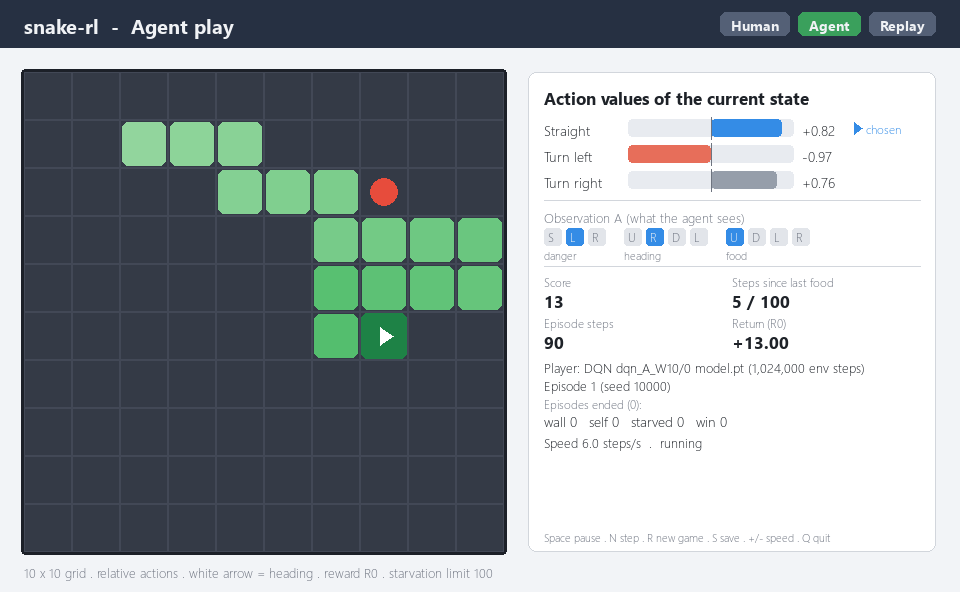

**Figure 1.** Agent-play mode of the interface: the DQN of the Part C submission (observation A, 10 × 10) at step 90 of evaluation board 10000, score 13. The bars are the action values of the current state: turn left is −0.97 because the cell to the left is the body (danger-left lit); the food is three cells above the head (food-up lit), behind that body, so neither safe move approaches it, and straight (+0.82) is preferred to right (+0.76) by a small margin. (The caption of the same frame in our Part D document misread the food as straight ahead.)

In [10]:
show_figure("Figure 1")

#### 5.2 Training settings (Section 4): Table 1

In [11]:
show_table("Table 1")

**Table 1.** Training settings of the learners. All DQN variants share these values unless a row of the matrix changes exactly the named key.

| Setting | Tabular Q-learning | DQN (MLP on A) | DQN (CNN on B) |
|---|---|---|---|
| Discount γ | 0.9 (0 for the control) | 0.9 main line; 0.99 on the discount axis | same |
| Step size / optimiser | α = 0.1 | Adam, 2.5 × 10⁻⁴, Huber loss, clip 10 | same |
| Exploration | ε 1.0 → 0.05, linear over the first 20 % of the steps; ε = 0 at evaluation | same | same |
| Parallel environments | 50 | 128 | 128 |
| Environment steps (8 × 8 / 10 × 10) | 500,000 / 1,000,000 | 512,000 / 1,024,000 | same |
| Network | table, 256 codes × 3 | 11–256–256–3 | conv 3 × 3 (32, 64, 64) – 512 – 3 |
| Replay / batch / warm-up | – | 100,000 / 256 / 10,000 steps | same |
| Gradient steps per vectorised step (G) | one update per step of the 50 boards | 32 (125,504 / 253,504 per run) | same |
| Target network | – | copied every 1,000 gradient steps (≈ 4,000 environment steps) | same |
| Device | CPU | CPU, 2 threads | GPU (RTX 5090) |
| Evaluation | every 25,000 / 50,000 steps | every 12,800 steps (41 / 81 evaluations) | same |
| Wall-clock per run (8 × 8 / 10 × 10) | 6 s / 9 s | 5 min / 10 min | 17–37 min / 37–53 min with five runs sharing the GPU |

#### 5.3 The questions and the answers (Section 6): Table 2

In [12]:
show_table("Table 2")

**Table 2.** The questions and the answers. Effects are paired differences with 95 % t intervals over five seeds (final policy unless stated); "rising" means the curve had not flattened when the budget ended.

| Question (axis) | Expected (Part B) | Found | Board; still rising? |
|---|---|---|---|
| Representation: grid (B8) against features (A) | A fast with a low ceiling; B slow with a high ceiling | +1.71 [+1.26, +2.15] at γ = 0.9; +0.40 [−0.83, +1.64]; B learns 4–14 times slower; at γ = 0.99 the gap is 5–7 points | 8 × 8; 10 × 10 (B8 near plateau) |
| Which planes: age plane (B8 vs B7), heading (B8 vs B3) | age plane necessary (Markov) | age plane: 8 × 8 none, 10 × 10 −1.15 [−2.00, −0.30] (B7 better); heading: −4.27 / −4.57 | both boards |
| Discount factor (0.9 → 0.99) | not an axis | A: −0.20 [−1.35, +0.96]; B8: +4.91 [+3.48, +6.34] and +5.03 [+4.26, +5.80], all survival time; on 8 × 8 not distinguishable from BFS | both; γ = 0.99 rising |
| Target network | stabilises training | none: −target +0.20 [−0.21, +0.61] (8 × 8), +0.34 [−0.51, +1.19] (10 × 10); no effect on overestimation | both |
| Replay | stabilises training | −9.26 [−11.64, −6.88] (8 × 8), −4.09 [−6.04, −2.15] (10 × 10); three factors, target staleness the largest on one path | both; see Table 6 |
| Replay ratio (63 → 2 uses per transition, target period matched) | not an axis | −1.21 [−1.97, −0.45] (8 × 8); +2.34 [+1.07, +3.60] (10 × 10), the best 10 × 10 agent at γ = 0.9 | 10 × 10 rising |
| Double DQN | less overestimation, better score | overestimation −0.87 [−0.95, −0.79] of +2.53 (B8, γ = 0.99); −0.39 of +6.14 (A, γ = 0.99); none at γ = 0.9; score: no consistent direction | 8 × 8 |
| Dueling; PER | better score | Dueling: score unchanged, B8 overestimation −0.08 [−0.11, −0.06]; PER: score −0.56 [−1.07, −0.06] (B8, last-5), slower | 8 × 8 |
| Reward: R1, R2, R3 against R0 | R2 safe, R3 exploitable | all within 1.4 points; R2 fastest start, worst finish (−1.10 [−1.56, −0.63], B8 γ = 0.99, last-10); R1 −0.95 [−1.54, −0.37] on 10 × 10; R3 ≥ R0, weakly | both |
| Reward hacking under R3 | expected | none at bonus 0.01 or 0.1; loops are value-estimation errors (Q in loops ≪ loop value) | 8 × 8 |

#### 5.4 The scale and the tabular reference (Section 6.1): Table 3 and Figure 2

**Table 3.** Headline results. Final = the policy after the last update; last-5 = mean of each agent's last five evaluations; both are means over five agents with a 95 % t interval over agents. Reference players: mean over the 100 episodes with a normal interval. Steps are means over the 500 (or 100) final-evaluation episodes; food per 100 steps is 100 × food / steps over a seed's 100 episodes, averaged over seeds; the last column pairs the agent with BFS on the same 100 boards (mean over boards per seed, t interval over seeds).

| Player | Score, final | Score, last-5 | Steps per episode | Food per 100 steps | Wall / self / starve (%) | Agent − BFS, same boards |
|---|---|---|---|---|---|---|
| **10 × 10 board** |  |  |  |  |  |  |
| Random | 0.18 ± 0.08 | – | 23.0 | – | 98 / 1 / 1 | – |
| BFS greedy | 30.61 ± 1.60 | – | 255.8 | 11.97 | 16 / 84 / 0 | – |
| Hamiltonian cycle | 97 (fills the board) | – | 2,409.7 | 4.03 | 0 / 0 / 0 | – |
| Tabular Q-learning (γ = 0.9) | 18.51 ± 1.10 | 18.14 ± 0.29 | 150.6 | 12.29 | 10 / 90 / 0 | −12.10 [−13.20, −11.00] |
| Tabular Q-learning, γ = 0 (control) | 19.69 ± 0.00 † | 19.69 ± 0.00 † | 239.2 | 8.23 | 4 / 96 / 0 | −10.92 † |
| DQN, observation A (MLP) | 20.29 ± 1.55 | 20.44 ± 1.41 | 167.8 | 12.10 | 16 / 84 / 0 | −10.32 [−11.87, −8.77] |
| DQN, observation B8 (CNN) | 20.69 ± 0.52 | 20.85 ± 0.59 | 187.6 | 11.03 | 7 / 93 / 0 | −9.92 [−10.44, −9.40] |
| DQN, B8, G = 1, target period 31 (`G1_t31`) | 23.03 ± 1.11 | 22.92 ± 0.78 | 196.3 | 11.73 | 1 / 99 / 0 | −7.58 [−8.69, −6.47] |
| DQN, B8, γ = 0.99 | 25.72 ± 0.83 | 25.46 ± 0.40 | 333.7 | 7.71 | 3 / 94 / 3 | −4.89 [−5.72, −4.07] |
| **8 × 8 board** |  |  |  |  |  |  |
| Random | 0.23 ± 0.10 | – | 13.2 | – | 98 / 2 / 0 | – |
| BFS greedy | 23.07 ± 1.13 | – | 151.4 | 15.24 | 35 / 65 / 0 | – |
| Hamiltonian cycle | 61 (fills the board) | – | 985.9 | 6.19 | 0 / 0 / 0 | – |
| Tabular Q-learning (γ = 0.9) | 15.67 ± 0.87 | 15.67 ± 0.40 | 102.0 | 15.37 | 19 / 81 / 0 | −7.40 [−8.28, −6.53] |
| Tabular Q-learning, γ = 0 (control) | 16.07 ± 0.10 † | 16.07 ± 0.10 † | 151.5 | 10.61 | 7 / 93 / 0 | −7.00 [−7.10, −6.90] † |
| DQN, observation A (MLP) | 16.11 ± 0.88 | 16.07 ± 0.64 | 104.9 | 15.36 | 21 / 79 / 0 | −6.96 [−7.85, −6.08] |
| DQN, observation B8 (CNN) | 17.81 ± 0.90 | 17.63 ± 0.28 | 131.4 | 13.55 | 5 / 95 / 0 | −5.26 [−6.16, −4.36] |
| DQN, B8, γ = 0.99 | 22.72 ± 1.04 | 22.39 ± 0.55 | 220.3 | 10.33 | 3 / 96 / 1 | −0.35 [−1.39, +0.70] |
| DQN, B8, γ = 0.99, R3 with bonus 0.1 | 24.44 ± 1.07 | 24.10 ± 0.57 | 237.0 | 10.32 | 4 / 96 / 1 | +1.37 [+0.29, +2.44] |

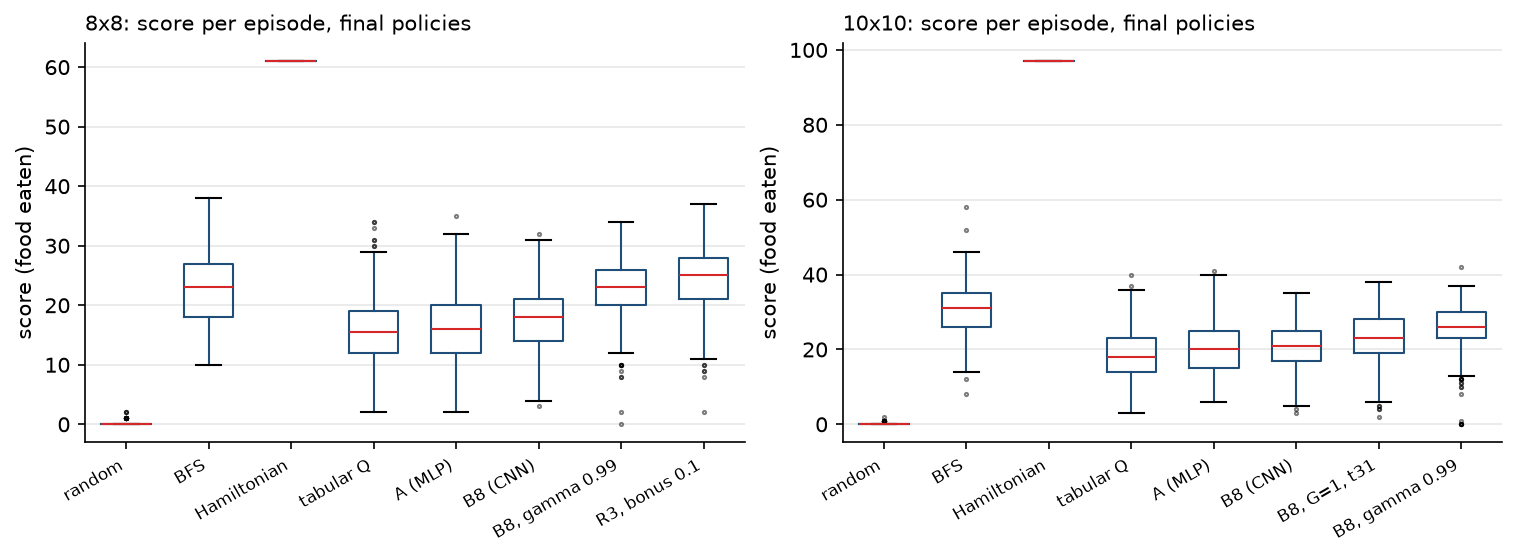

**Figure 2.** Score per episode of the final policies on 8 × 8 (left) and 10 × 10 (right): box = quartiles and median, whiskers = 1.5 interquartile ranges, dots = outliers; reference players over their 100 episodes, learners over the 500 episodes of their five seeds. The learned policies' distributions have the planner's shape shifted down; only the γ = 0.99 agent on 8 × 8 and the probe overlap BFS, and a few of their episodes score 0–2 (loops; Section 6.8). The Hamiltonian cycle scores the same in every game.

In [13]:
show_table("Table 3", tables.get("Table 3"))
show_figure("Figure 2")

#### 5.5 State representation (Section 6.2): Table 4 and Figure 3

**Table 4.** The representation axis (DQN, γ = 0.9, 5 seeds). Paired differences are against B8 on the same seeds, final / last-5.

| Observation | 8 × 8, final | 8 × 8, last-5 | 8 × 8, minus B8 | 10 × 10, final | 10 × 10, last-5 | 10 × 10, minus B8 |
|---|---|---|---|---|---|---|
| A: 11 features, MLP | 16.11 ± 0.88 | 16.07 ± 0.64 | −1.71 [−2.15, −1.26] / −1.56 [−2.04, −1.08] | 20.29 ± 1.55 | 20.44 ± 1.41 | −0.40 [−1.64, +0.83] / −0.40 [−1.47, +0.66] |
| B3: head, body, food | 13.54 ± 0.61 | 13.48 ± 0.36 | −4.27 [−5.39, −3.15] / −4.15 [−4.58, −3.71] | 16.12 ± 0.25 | 15.81 ± 0.33 | −4.57 [−5.09, −4.05] / −5.04 [−5.64, −4.45] |
| B7: B8 without the age plane | 18.18 ± 0.85 | 17.93 ± 0.81 | +0.37 [−1.00, +1.74] / +0.30 [−0.40, +1.00] | 21.84 ± 0.74 | 21.49 ± 0.43 | +1.15 [+0.30, +2.00] / +0.64 [−0.24, +1.53] |
| B8: head, body, food, age, heading × 4 | 17.81 ± 0.90 | 17.63 ± 0.28 | – | 20.69 ± 0.52 | 20.85 ± 0.59 | – |

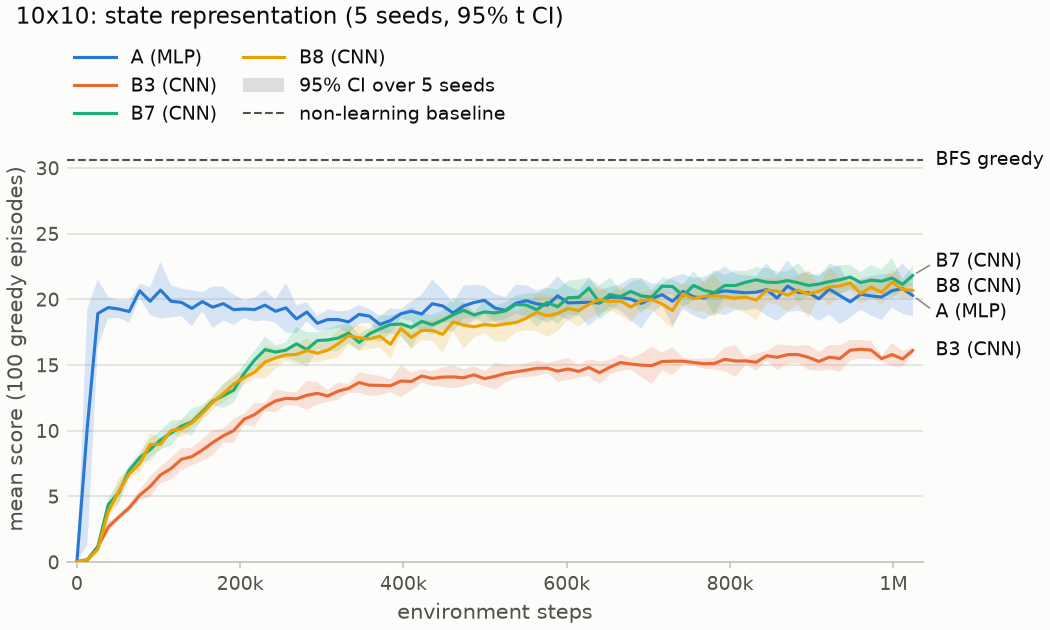

**Figure 3.** The representation axis on 10 × 10: greedy score during training, mean over five seeds with a 95 % t band; BFS as the dashed line. Observation A is at its level after the first evaluations and dips between 290k and 450k steps; B8 and B7 reach 15 points after about 230k steps and A's level after about 500k; B3 (no heading) stays 4–5 points lower throughout.

In [14]:
show_table("Table 4", tables.get("Table 4"))
show_figure("Figure 3")

#### 5.6 Discount factor (Section 6.3): Table 5 and Figure 4

**Table 5.** The discount axis (DQN, 5 seeds). Paired differences are γ = 0.99 minus γ = 0.9 on the same seeds.

|  | 8 × 8, γ = 0.9 | 8 × 8, γ = 0.99 | 8 × 8, paired | 10 × 10, γ = 0.9 | 10 × 10, γ = 0.99 | 10 × 10, paired |
|---|---|---|---|---|---|---|
| A (MLP), final | 16.11 ± 0.88 | 15.91 ± 0.60 | −0.20 [−1.35, +0.96] | 20.29 ± 1.55 | not run | – |
| B8 (CNN), final | 17.81 ± 0.90 | 22.72 ± 1.04 | +4.91 [+3.48, +6.34] (5/5) | 20.69 ± 0.52 | 25.72 ± 0.83 | +5.03 [+4.26, +5.80] (5/5) |
| B8, last-5 | 17.63 ± 0.28 | 22.39 ± 0.55 | +4.76 [+4.45, +5.08] | 20.85 ± 0.59 | 25.46 ± 0.40 | +4.61 [+4.11, +5.12] |
| B8, steps per episode | 131.4 | 220.3 |  | 187.6 | 333.7 | +146 [+130, +162] |
| B8, food per 100 steps | 13.55 ± 0.13 | 10.33 ± 0.45 |  | 11.03 ± 0.11 | 7.71 ± 0.26 | −3.32 [−3.64, −3.00] |
| B8, starvation rate | 0.00 | 0.01 |  | 0.00 | 0.03 | +0.03 [+0.01, +0.05] |
| B8, overestimation on visited states (ratio) | +0.30 (1.26) | +2.53 (1.50) |  | +0.24 (1.25) | +3.68 (1.78) |  |
| B8, minus BFS on the same boards | −5.26 [−6.16, −4.36] | −0.35 [−1.39, +0.70] |  | −9.92 [−10.44, −9.40] | −4.89 [−5.72, −4.07] |  |

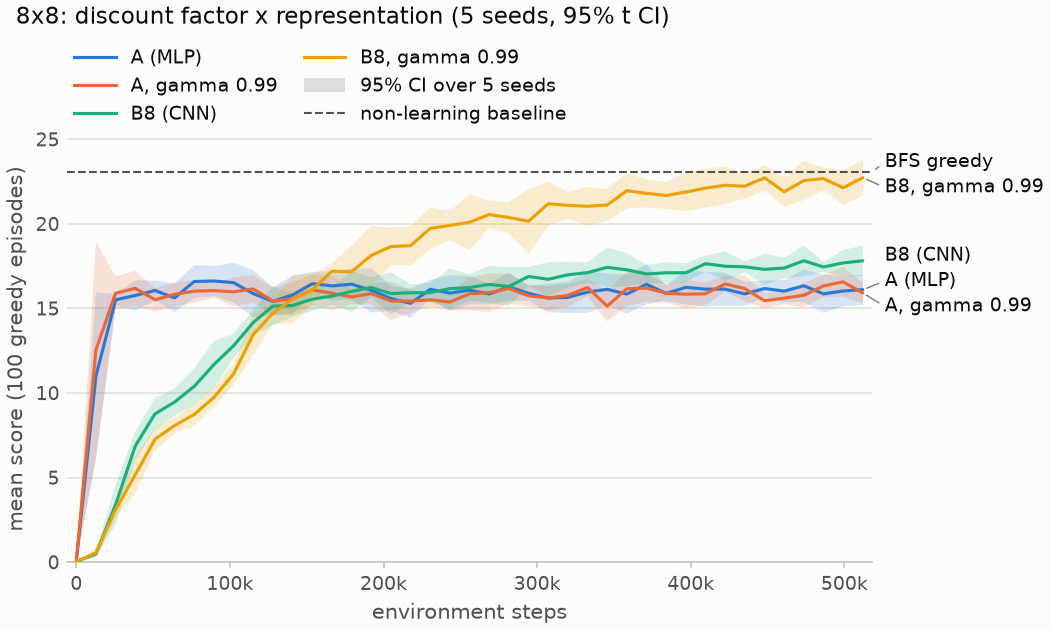

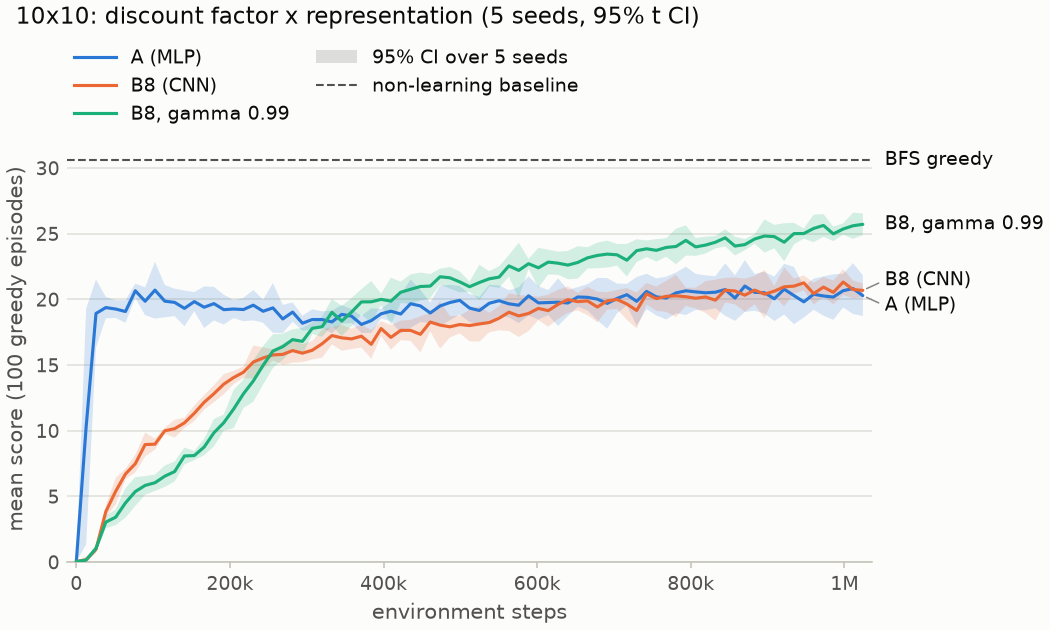

**Figure 4.** The discount axis on 8 × 8 (left) and 10 × 10 (right). At γ = 0.9 the other learners (A at both discounts, B8 at γ = 0.9) sit within two points of each other; the convolutional agent at γ = 0.99 separates from them after 150k (8 × 8) or 350k (10 × 10) steps and ends within the planner's interval on 8 × 8.

In [15]:
show_table("Table 5", tables.get("Table 5"))
show_figure("Figure 4")

#### 5.7 The stabilisers (Section 6.4): Table 6, Figures 5 and 6

**Table 6.** The component axis on observation B8 (5 seeds). The target period is in gradient steps, with its equivalent in environment steps; G is the number of gradient steps per vectorised step of the 128 boards; the short names are those used in the text.

| Configuration | Replay | G | Target period | 8 × 8, final | 8 × 8, last-5 | 10 × 10, final | 10 × 10, last-5 |
|---|---|---|---|---|---|---|---|
| B8, full | yes | 32 | 1,000 (≈ 4k env steps) | 17.81 ± 0.90 | 17.63 ± 0.28 | 20.69 ± 0.52 | 20.85 ± 0.59 |
| no target network | yes | 32 | 1 | 18.01 ± 0.67 | 18.16 ± 0.63 | 21.03 ± 0.55 | 21.45 ± 0.40 |
| no replay | no | 1 | 1,000 (= 128k env steps) | 8.55 ± 3.09 | 8.38 ± 3.32 | 16.60 ± 2.33 | 16.03 ± 2.81 |
| no replay, no target network | no | 1 | 1 | 13.90 ± 0.84 | 13.70 ± 0.65 | not run | – |
| no replay, target period matched (`t31`) | no | 1 | 31 (≈ 4k env steps) | 14.03 ± 1.39 | 13.98 ± 0.77 | 21.70 ± 1.07 | 20.67 ± 0.63 |
| replay, G = 1 (`G1`) | yes | 1 | 1,000 (= 128k env steps) | 13.73 ± 3.38 | 11.83 ± 2.15 | not run | – |
| replay, G = 1, target period matched (`G1_t31`) | yes | 1 | 31 (≈ 4k env steps) | 16.60 ± 0.82 | 16.11 ± 0.65 | 23.03 ± 1.11 | 22.92 ± 0.78 |

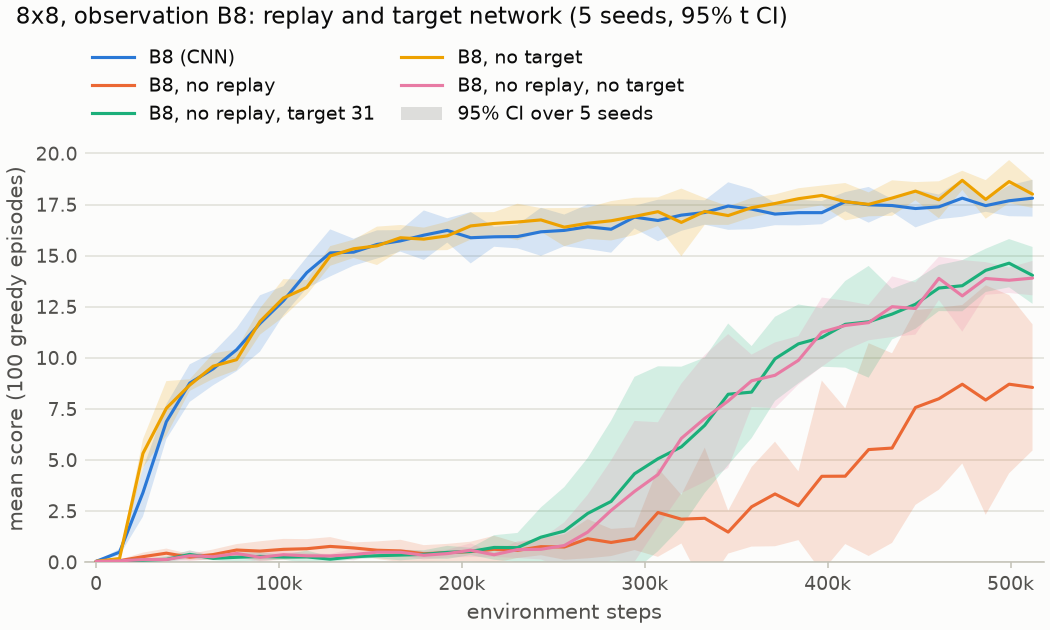

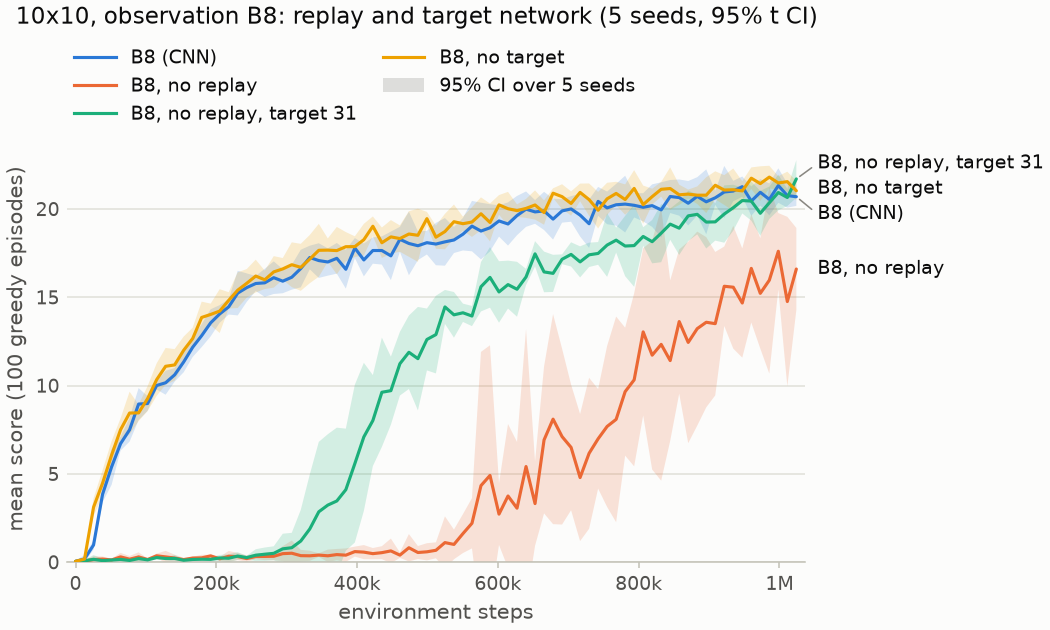

**Figure 5.** Replay and target network on observation B8, 8 × 8 (left) and 10 × 10 (right). Without a target network the curve is indistinguishable from the full agent's. Without replay the agent learns nothing for 250k–500k steps; matching the target period in environment steps ("target 31") recovers most of the loss, and on 10 × 10 the two curves meet at the end of the budget.

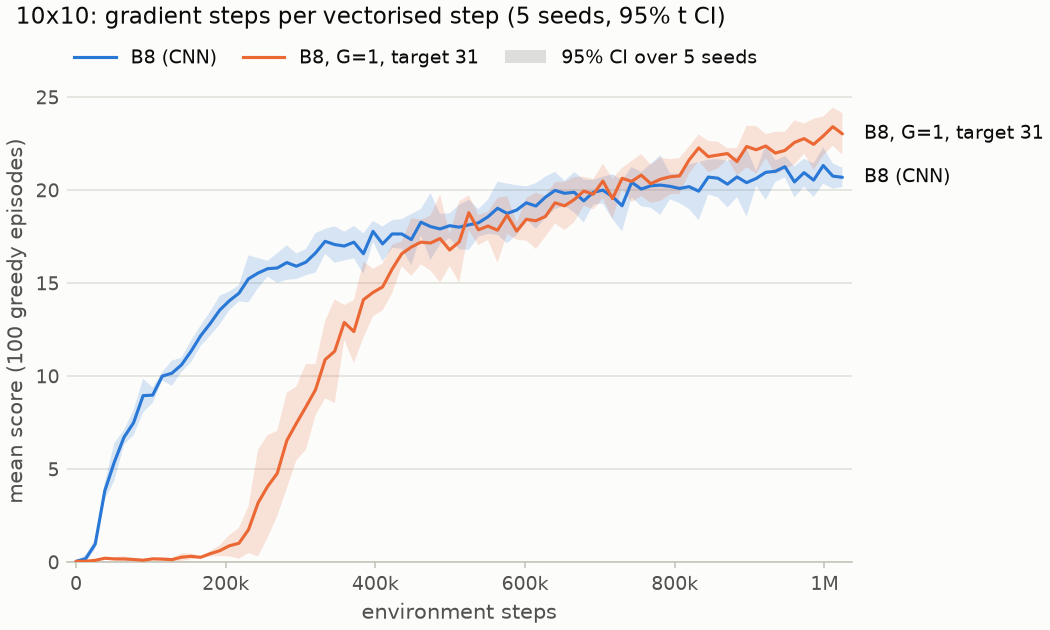

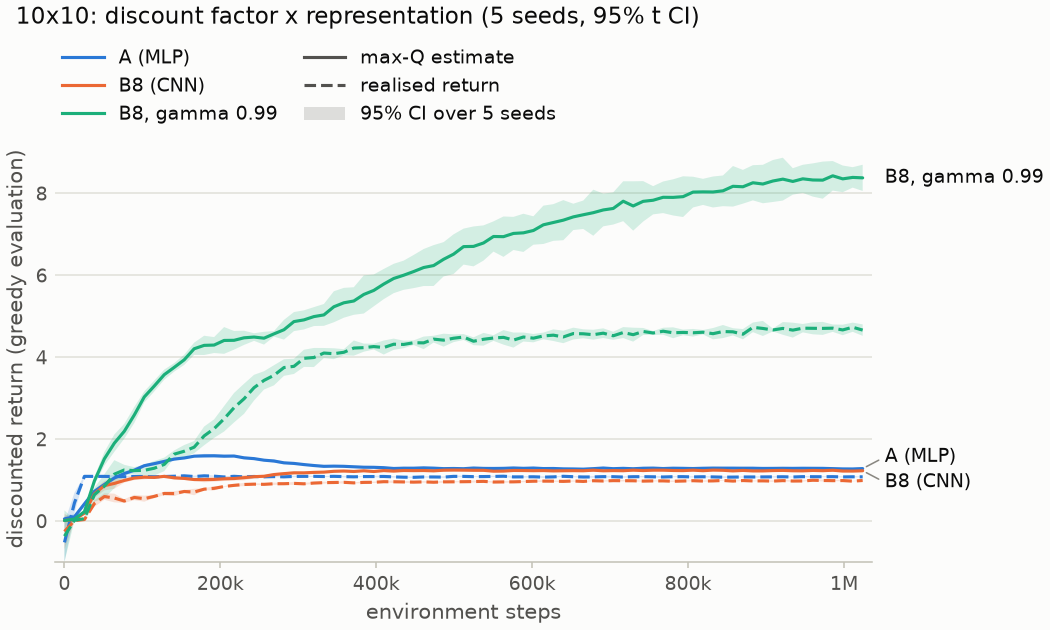

**Figure 6.** (a) One gradient step per vectorised step with the target period matched (`G1_t31`) against the full agent on 10 × 10: slower for 400k steps, then higher and still rising. (b) The overestimation measurement on 10 × 10: solid lines are the network's max_a Q on the states its greedy policy visits, dashed lines the discounted return it then realises. At γ = 0.9 the gap is 0.2–0.25; at γ = 0.99 the estimate climbs to 8.4 against a return of 4.7.

In [16]:
show_table("Table 6", tables.get("Table 6"))
show_figure("Figure 5")
show_figure("Figure 6")

#### 5.8 Double DQN, Dueling and prioritised replay (Section 6.5): Table 7 and Figure 7

**Table 7.** The refinements on 8 × 8 (5 seeds). Score differences are variant minus baseline, paired by seed, for the final / last-5 / last-20 windows; the overestimation gap is estimate minus realised return on visited states, mean of the last five evaluations, baseline → variant.

| Baseline → variant | Baseline score | Variant score | Score difference: final / last-5 / last-20 | Overestimation gap, visited states | Start-state gap |
|---|---|---|---|---|---|
| A, γ = 0.9 → Double | 16.11 ± 0.88 | 17.21 ± 0.59 | +1.11 [+0.12, +2.10] / +1.07 [+0.34, +1.79] / +0.68 [+0.02, +1.34] | 0.25 → 0.25 | −0.21 → −0.20 |
| A, γ = 0.99 → Double | 15.91 ± 0.60 | 16.37 ± 0.80 | +0.46 [−0.42, +1.34] / +0.57 [−0.00, +1.15] / +0.54 [+0.08, +1.00] | 6.14 → 5.75 (−0.39 [−0.58, −0.21]) | 2.05 → 1.54 |
| A, γ = 0.9 → Dueling | 16.11 ± 0.88 | 15.45 ± 0.87 | −0.66 [−1.65, +0.33] / −0.41 [−1.25, +0.43] / −0.34 [−1.03, +0.35] | 0.25 → 0.23 (−0.02 [−0.03, −0.01]) | −0.21 → −0.23 |
| A, γ = 0.9 → PER | 16.11 ± 0.88 | 15.84 ± 0.78 | −0.27 [−1.59, +1.06] / −0.14 [−1.38, +1.10] / −0.09 [−1.27, +1.10] | 0.25 → 0.27 | −0.21 → −0.20 |
| B8, γ = 0.9 → Double | 17.81 ± 0.90 | 17.69 ± 0.56 | −0.12 [−1.22, +0.98] / −0.06 [−0.54, +0.42] / −0.07 [−0.40, +0.26] | 0.30 → 0.27 (−0.03 [−0.06, −0.01]) | 0.17 → 0.14 |
| B8, γ = 0.99 → Double | 22.72 ± 1.04 | 22.38 ± 1.10 | −0.34 [−1.70, +1.02] / −0.50 [−1.20, +0.21] / −0.89 [−1.68, −0.11] | 2.53 → 1.66 (−0.87 [−0.95, −0.79]) | 0.52 → −0.13 |
| B8, γ = 0.9 → Dueling | 17.81 ± 0.90 | 18.09 ± 0.93 | +0.28 [−0.71, +1.26] / +0.21 [−0.44, +0.85] / +0.02 [−0.25, +0.28] | 0.30 → 0.22 (−0.08 [−0.11, −0.06]) | 0.17 → 0.16 |
| B8, γ = 0.9 → PER | 17.81 ± 0.90 | 17.14 ± 1.08 | −0.67 [−2.26, +0.91] / −0.56 [−1.07, −0.06] / −0.83 [−1.29, −0.36] | 0.30 → 0.28 | 0.17 → 0.15 |

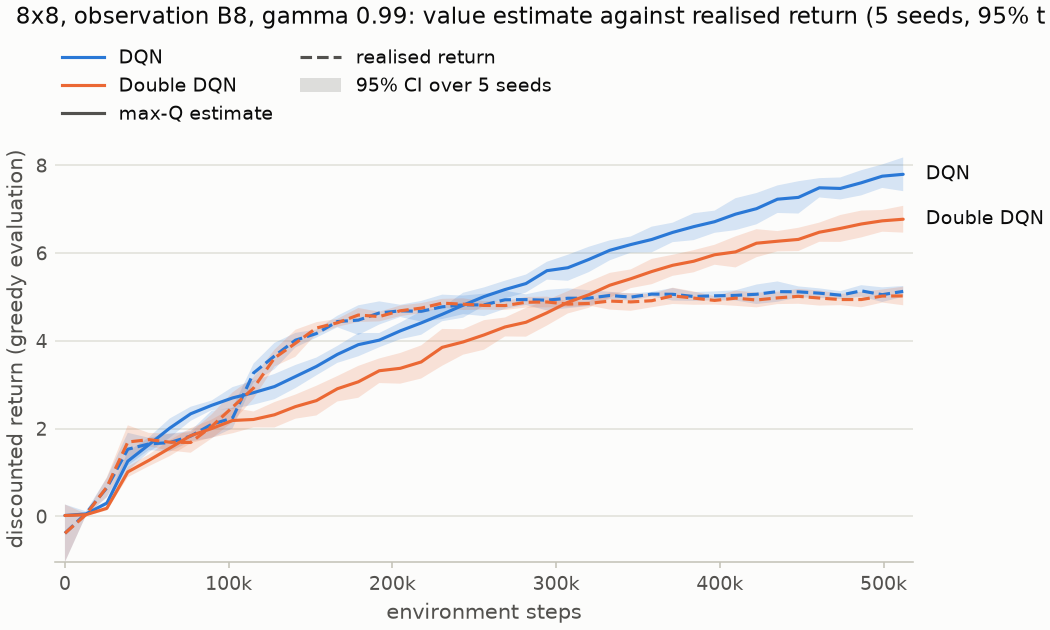

**Figure 7.** Double DQN against DQN on observation B8 at γ = 0.99 (8 × 8): the max-Q estimate on visited states (solid) against the realised return (dashed). Both estimates lag the return until about 250k steps and then overtake it; Double DQN's rises more slowly and ends a third closer to it. The realised returns of the two agents are the same.

In [17]:
show_table("Table 7", tables.get("Table 7"))
show_figure("Figure 7")

#### 5.9 Reward design (Section 6.6): Table 8, Figures 8 and 9

**Table 8.** The reward axis: score (food eaten) of the final policy, 5 seeds, and paired differences against R0. 8 × 8 differences are final / last-10; 10 × 10 differences are last-5.

| Reward | A, γ = 0.9 | A, γ = 0.99 | B8, γ = 0.9 | B8, γ = 0.99 | B8, γ = 0.99, 10 × 10 |
|---|---|---|---|---|---|
| R0, sparse | 16.11 ± 0.88 | 15.91 ± 0.60 | 17.81 ± 0.90 | 22.72 ± 1.04 | 25.72 ± 0.83 |
| R1, step penalty | 16.47 ± 0.30 | 16.10 ± 1.07 | 17.56 ± 0.46 | 22.72 ± 1.49 | 24.72 ± 0.64 |
| R2, potential-based shaping | 16.13 ± 0.41 | 15.62 ± 0.93 | 17.12 ± 0.62 | 21.59 ± 0.62 | 25.27 ± 0.71 |
| R3, naive distance shaping | 16.81 ± 1.36 | 16.10 ± 0.57 | 18.08 ± 0.89 | 23.52 ± 0.92 | 25.76 ± 0.67 |
| R3 symmetric (± 0.01) | – | 15.58 ± 0.64 | – | 22.88 ± 1.10 | – |
| R3, starvation limit 1,000 | – | 16.10 ± 0.57 | – | 23.15 ± 0.77 | – |
| R3, bonus 0.1 (probe) | – | – | – | 24.44 ± 1.07 | – |
| BFS greedy, same boards | 23.07 ± 1.13 |  |  |  | 30.61 ± 1.60 |
| R1 − R0 | +0.37 [−0.80, +1.53] / +0.22 [−0.86, +1.29] | +0.19 [−1.23, +1.61] / +0.10 [−0.46, +0.66] | −0.25 [−1.25, +0.75] / −0.01 [−0.24, +0.22] | +0.00 [−0.94, +0.95] / −0.45 [−1.25, +0.36] | −0.95 [−1.54, −0.37] |
| R2 − R0 | +0.02 [−0.83, +0.87] / +0.12 [−0.27, +0.51] | −0.29 [−1.20, +0.61] / −0.25 [−0.54, +0.04] | −0.69 [−1.85, +0.47] / −0.49 [−1.13, +0.15] | −1.13 [−2.33, +0.07] / −1.10 [−1.56, −0.63] | −0.40 [−1.04, +0.24] |
| R3 − R0 | +0.70 [−0.72, +2.12] / +0.40 [−0.45, +1.25] | +0.19 [−0.80, +1.19] / −0.21 [−0.59, +0.18] | +0.27 [−0.61, +1.15] / +0.41 [−0.14, +0.97] | +0.80 [−0.84, +2.43] / +0.47 [+0.31, +0.62] | +0.34 [−0.33, +1.01] |

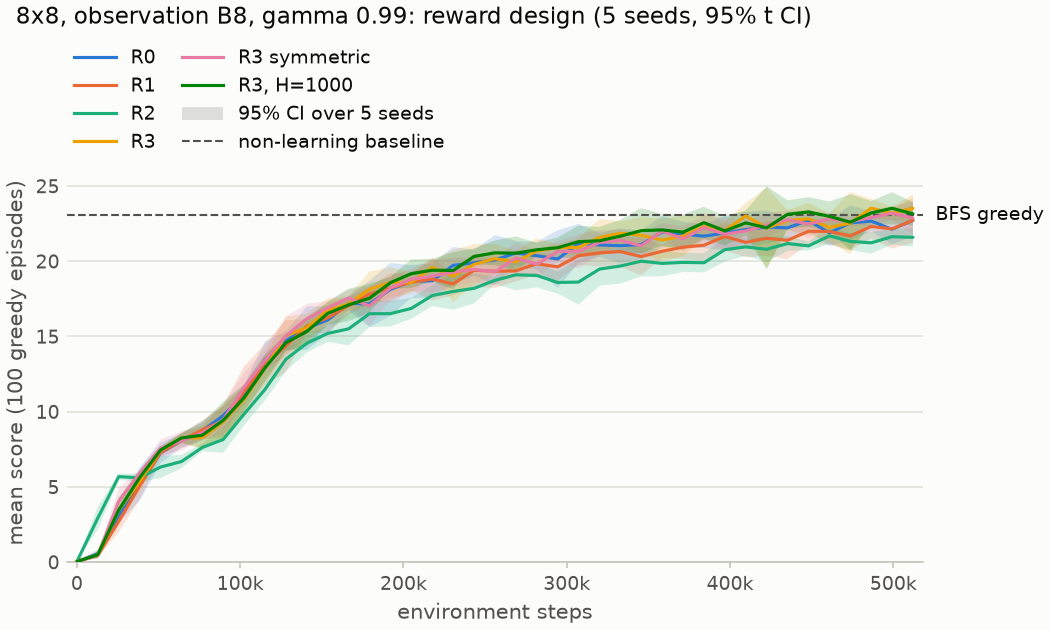

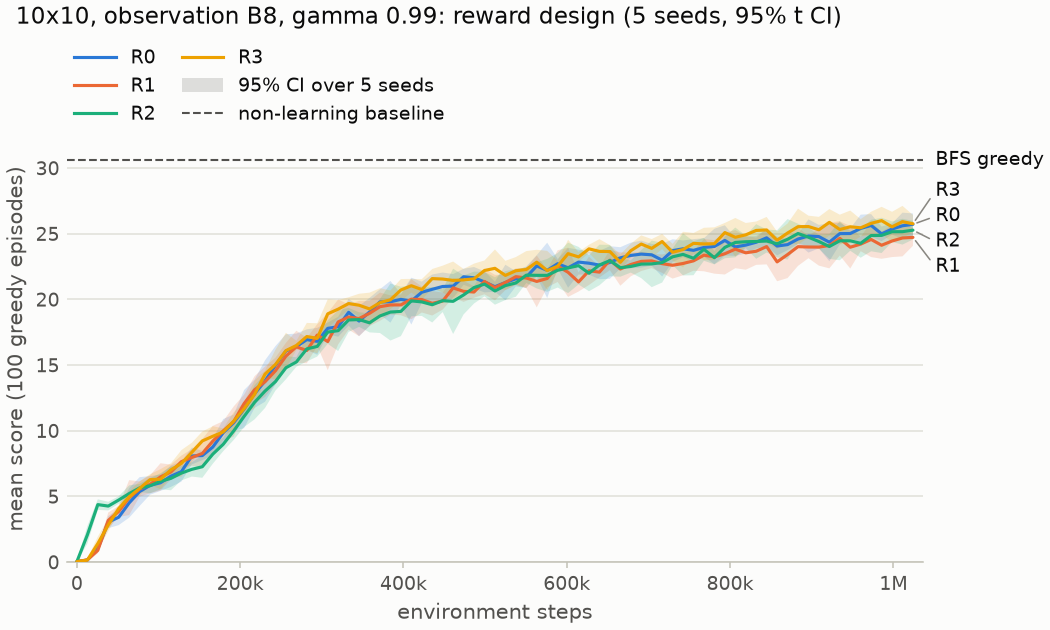

**Figure 8.** The reward axis on observation B8 at γ = 0.99, 8 × 8 (left, with the two hacking probes) and 10 × 10 (right). The curves are within a point of each other for most of training; R2 is highest at the first evaluation and lowest at the end on 8 × 8.

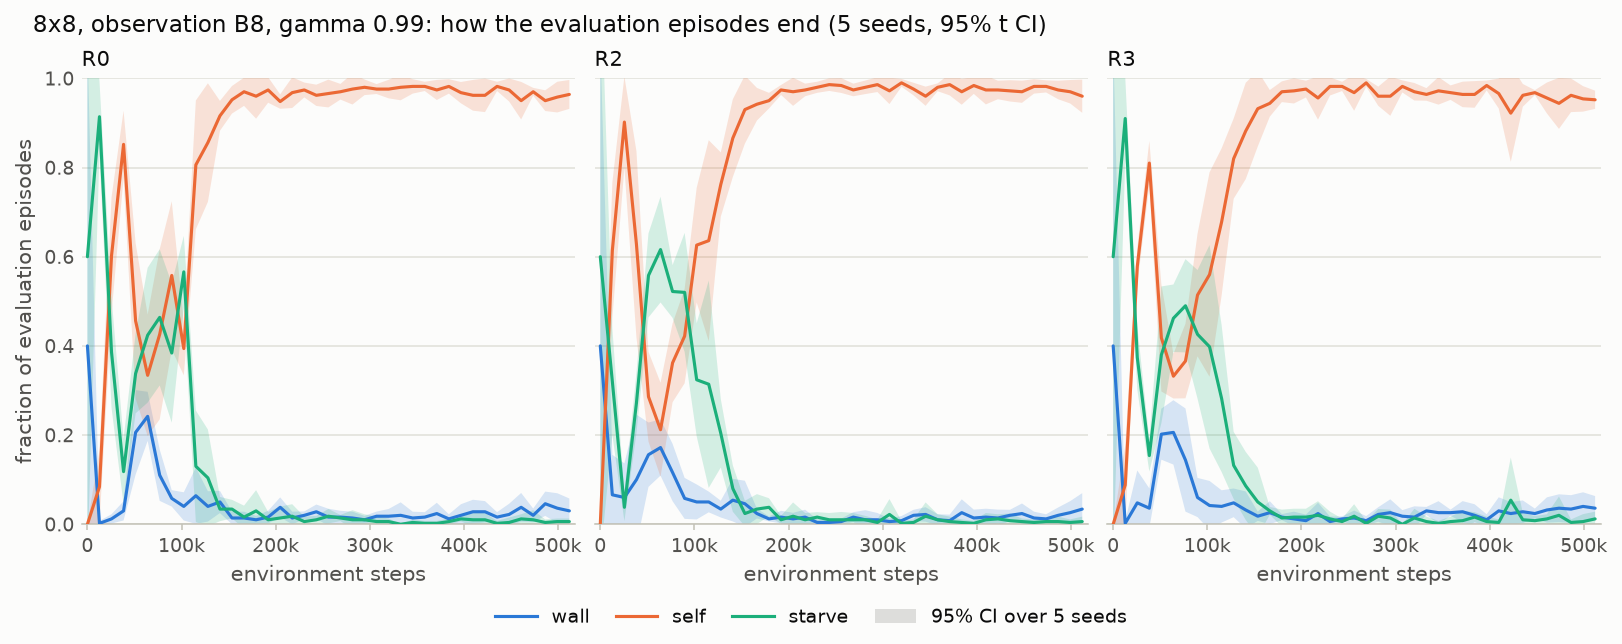

**Figure 9.** How the evaluation episodes end during training, observation B8, γ = 0.99, 8 × 8, for R0, R2 and R3 (wall, self, starvation; mean over seeds with t bands; the panels of R1 and of the two probes, in the generated report, have the same shape). Every variant goes through the same three stages: starvation while the agent cannot find food (0–100k steps), a wall-collision peak as it starts to move purposefully, then almost exclusively self-collision. R2's starvation peak at 12.8k steps is much lower (0.3 against 0.9) and its later one higher. No reward produces a late rise in starvation.

In [18]:
show_table("Table 8", tables.get("Table 8"))
show_figure("Figure 8")
show_figure("Figure 9")

#### 5.10 Reward hacking, the probe (Section 6.7): Figure 10

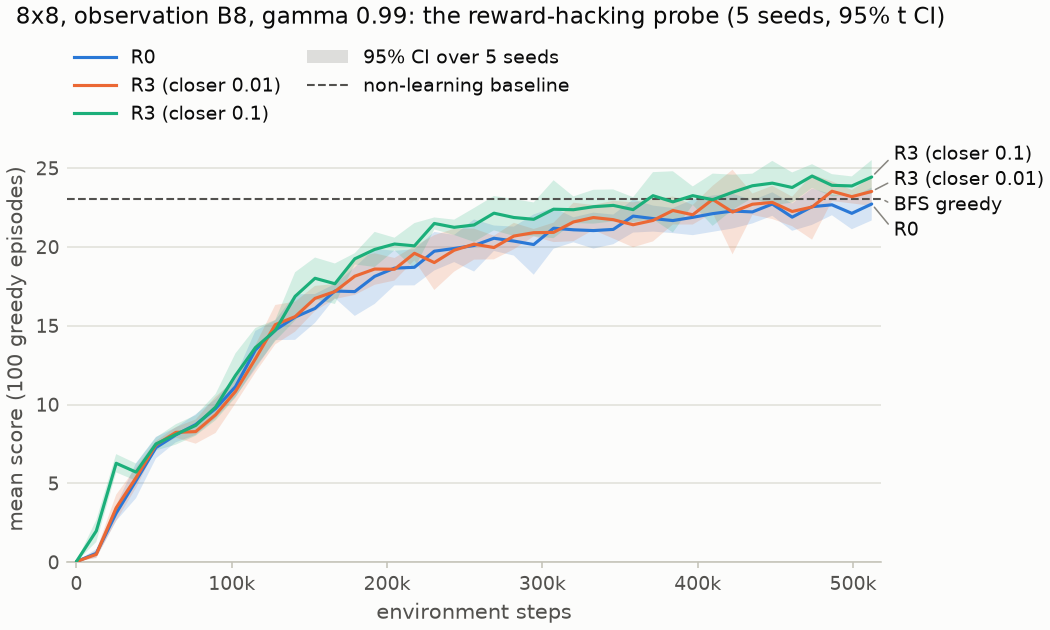

**Figure 10.** The hacking probe: R3 with the closer-step bonus raised from 0.01 to 0.1, against R3 and R0 (B8, γ = 0.99, 8 × 8). The larger bonus learns faster from the first evaluation and ends highest, above the BFS line.

In [19]:
show_figure("Figure 10")

#### 5.11 Behaviour (Section 6.8): Table 9, Figures 11 to 13

**Table 9.** Behaviour of the final policies on 10 × 10, 100 evaluation episodes per player (DQN rows: mean over 5 seeds ± t interval where it is not negligible). Border share is the mean over episodes of the share of states on the outer ring (uniform: 0.36; the heat-map titles of Figures 11 and 12 pool all visited states instead, which weights long episodes more and differs by a few points); loops are episodes whose post-food tail repeats for 20 states or more; Q in loops is the mean max_a Q in those episodes against the others.

| Player | Score | Steps | Self / wall / starve | Border share | Looping episodes | Q estimate: loops / others | Tail after last food (steps) |
|---|---|---|---|---|---|---|---|
| BFS greedy | 30.61 | 255.8 | 0.84 / 0.16 / 0 | 0.27 | 0 | – | 9.2 |
| Hamiltonian cycle | 97 (all won) | 2,409.7 | – | 0.36 | 0 | – | 0 |
| B8, γ = 0.9 | 20.71 ± 0.52 | 187.8 ± 5.3 | 0.94 / 0.06 / 0 | 0.22 ± 0.01 | 0 | – | 7.0 ± 0.7 |
| B8, γ = 0.99, 51k steps | 6.04 ± 0.62 | 136.1 ± 23.6 | 0.31 / 0.17 / 0.52 | 0.35 ± 0.04 | 0.45 ± 0.15 (227) | 3.12 / 3.12 | 59.8 ± 14.3 |
| B8, γ = 0.99, 256k steps | 20.95 ± 0.34 | 250.6 ± 2.2 | 0.98 / 0.00 / 0.014 | 0.27 ± 0.03 | 0.006 (3) | 9.65 / 6.96 | 15.0 ± 2.2 |
| B8, γ = 0.99, final | 25.75 ± 0.81 | 334.0 ± 13.7 | 0.94 / 0.03 / 0.032 | 0.25 ± 0.01 | 0.012 (6) | 12.08 / 8.61 | 17.7 ± 3.4 |
| B8, γ = 0.99, R1, final | 24.70 ± 0.74 | 321.6 ± 17.9 | 0.95 / 0.02 / 0.030 | 0.26 ± 0.02 | 0.008 (4) | 11.33 / 7.80 | 18.0 ± 2.1 |
| B8, γ = 0.99, R2, final | 25.19 ± 0.66 | 320.7 ± 15.7 | 0.95 / 0.03 / 0.024 | 0.26 ± 0.02 | 0.012 (6) | 11.18 / 8.87 | 16.9 ± 2.3 |
| B8, γ = 0.99, R3, final | 25.75 ± 0.69 | 324.0 ± 10.0 | 0.93 / 0.04 / 0.024 | 0.25 ± 0.02 | 0.014 (7) | 12.34 / 9.53 | 16.7 ± 2.9 |

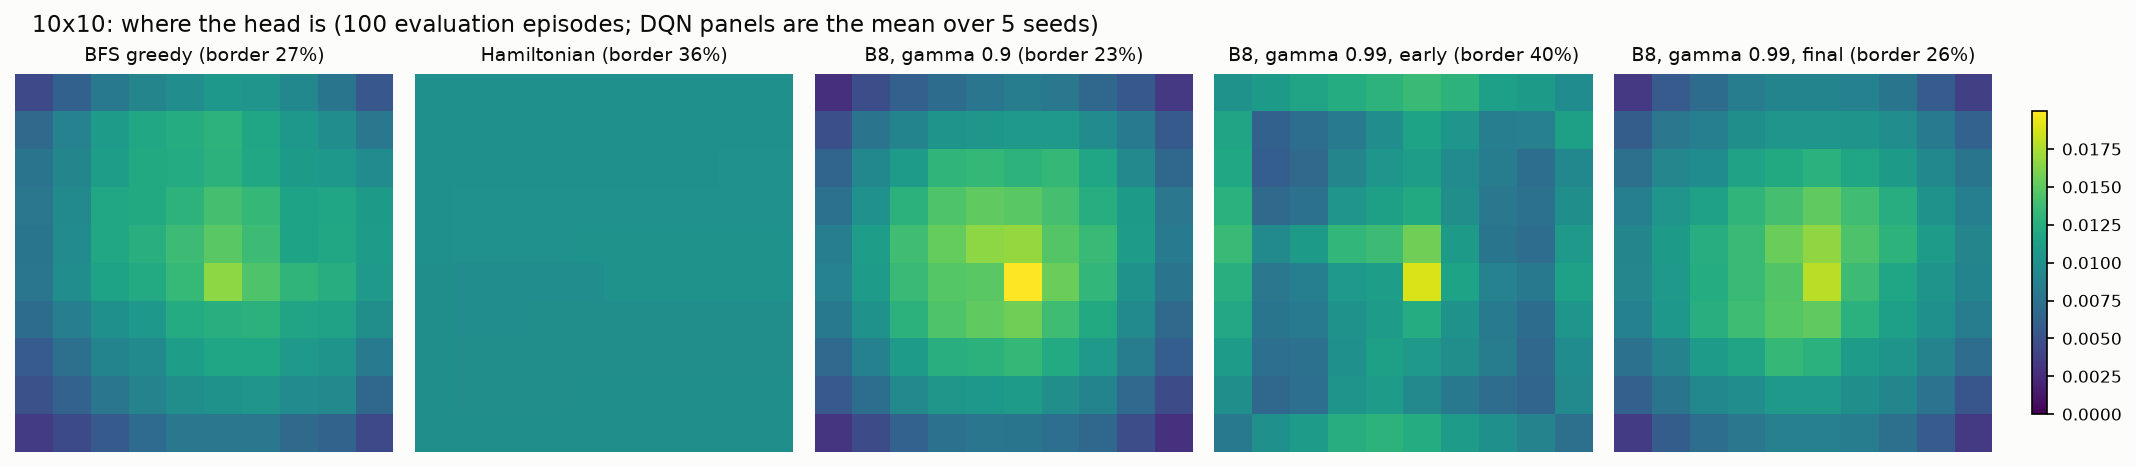

**Figure 11.** Where the head is on 10 × 10, over the 100 evaluation episodes, one colour scale; the panel titles give the share of all visited states on the outer ring (pooled, so long episodes weigh more). The planner and all learned policies concentrate in the middle; the Hamiltonian cycle is uniform by construction; the early γ = 0.99 checkpoint, which loops in half its episodes, is the only learned one whose pooled visits exceed the uniform border share.

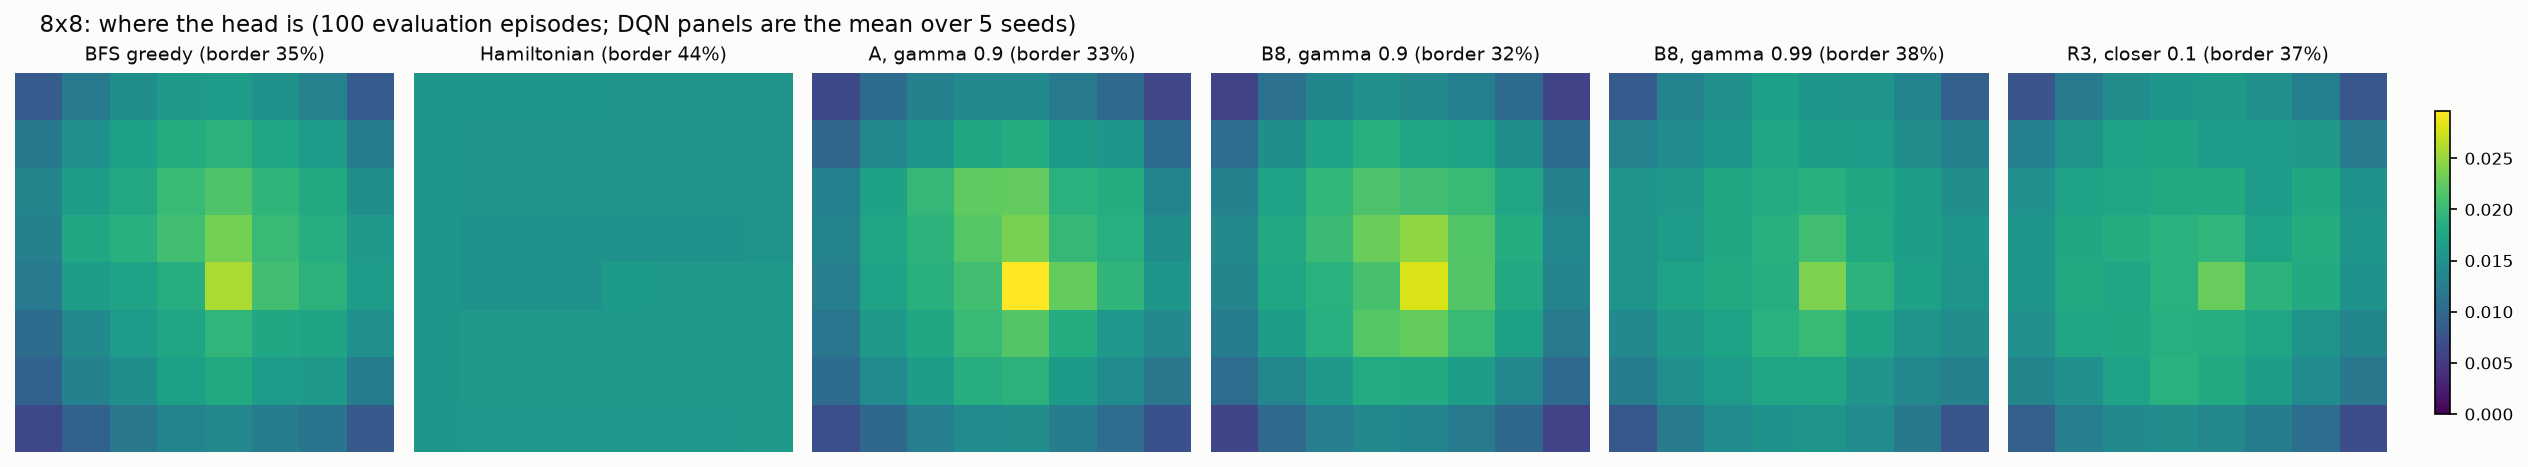

**Figure 12.** The same on 8 × 8 for BFS, the Hamiltonian cycle, the feature-vector agent, the convolutional agent at both discounts and the hacking probe. The probe's distribution is that of the other agents: nothing in it suggests circling.

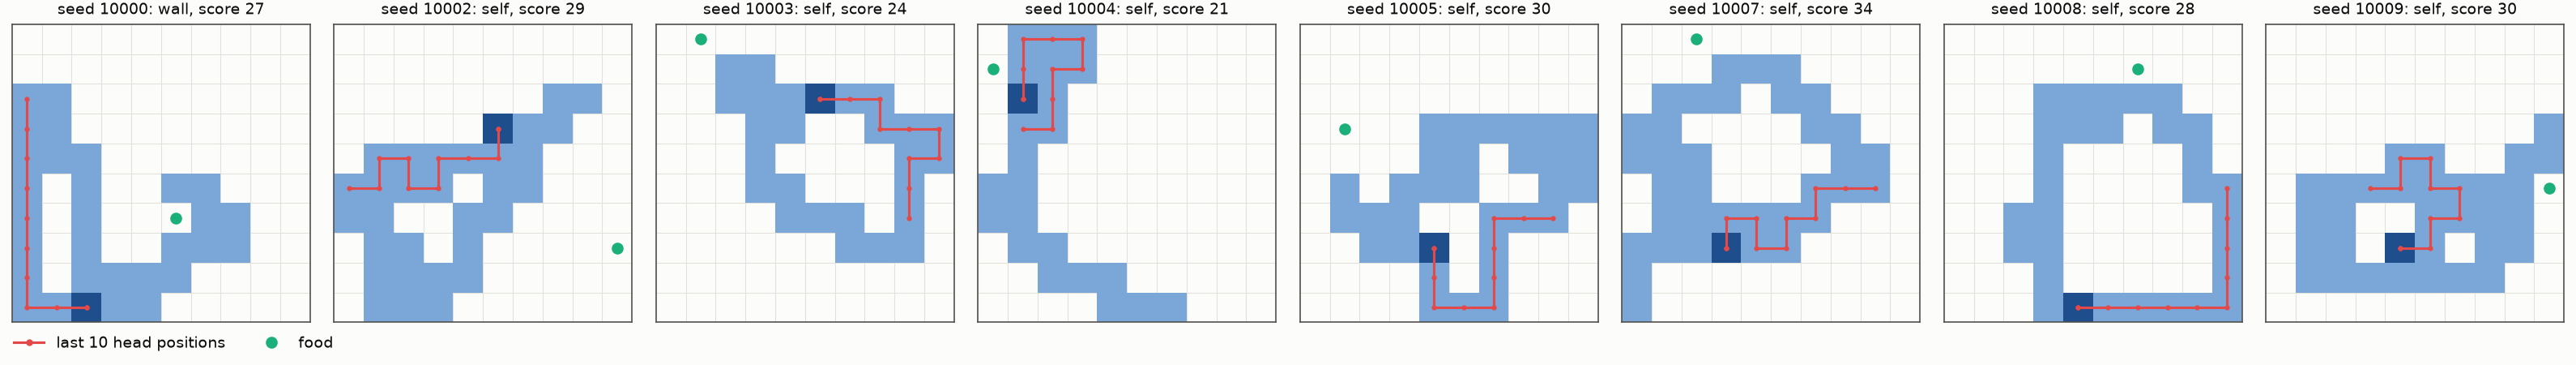

**Figure 13.** The final board of eight evaluation episodes of one γ = 0.99 agent (seed 0, 10 × 10): the body in blue with the head darker, the last ten head positions in red, the food in green. Every death but one is a self-collision inside a pocket the snake has closed around itself, with the food out of reach; the one wall collision (board 10000) is a corridor along the edge with no exit.

In [20]:
show_table("Table 9", tables.get("Table 9"))
show_figure("Figure 11")
show_figure("Figure 12")
show_figure("Figure 13")

#### 5.12 Every configuration (Appendix B): Tables B1 and B2

In [21]:
# The columns of the report from the generated summary tables of both boards
for name, W in (("Table B1", 8), ("Table B2", 10)):
    show_table(name, rt.appendix_table(f"runs/report/tables/summary_W{W}.md"))

**Table B1.** 8 × 8, every configuration (512,000 environment steps per learner run; tabular Q-learning 500,000).

| Configuration | Score, final | Score, last-5 | Steps | Wall | Self | Starve |
|---|---|---|---|---|---|---|
| random | 0.23 ± 0.10 | n/a | 13.2 | 0.98 | 0.02 | 0.00 |
| BFS greedy | 23.07 ± 1.13 | n/a | 151.4 | 0.35 | 0.65 | 0.00 |
| Hamiltonian | 61.00 ± 0.00 | n/a | 985.9 | 0.00 | 0.00 | 0.00 |
| tabular Q | 15.67 ± 0.87 | 15.67 ± 0.40 | 102.0 | 0.19 | 0.81 | 0.00 |
| tabular Q, gamma 0 | 16.07 ± 0.10 | 16.07 ± 0.10 | 151.5 | 0.07 | 0.93 | 0.00 |
| A (MLP) | 16.11 ± 0.88 | 16.07 ± 0.64 | 104.9 | 0.21 | 0.79 | 0.00 |
| B8 (CNN) | 17.81 ± 0.90 | 17.63 ± 0.28 | 131.4 | 0.05 | 0.95 | 0.00 |
| B3 (CNN) | 13.54 ± 0.61 | 13.48 ± 0.36 | 100.6 | 0.18 | 0.82 | 0.01 |
| B7 (CNN) | 18.18 ± 0.85 | 17.93 ± 0.81 | 135.1 | 0.08 | 0.92 | 0.00 |
| A, gamma 0.99 | 15.91 ± 0.60 | 16.04 ± 0.20 | 103.0 | 0.20 | 0.80 | 0.00 |
| B8, gamma 0.99 | 22.72 ± 1.04 | 22.39 ± 0.55 | 220.3 | 0.03 | 0.96 | 0.01 |
| A, no replay | 15.39 ± 0.80 | 15.68 ± 0.71 | 99.2 | 0.01 | 0.99 | 0.00 |
| A, no replay, target 31 | 15.54 ± 0.68 | 15.24 ± 0.49 | 100.0 | 0.02 | 0.98 | 0.00 |
| A, no target | 16.61 ± 1.04 | 16.59 ± 0.60 | 110.5 | 0.26 | 0.74 | 0.00 |
| A, no replay, no target | 15.43 ± 0.81 | 15.43 ± 0.47 | 100.0 | 0.01 | 0.99 | 0.00 |
| B8, no replay | 8.55 ± 3.09 | 8.38 ± 3.32 | 126.9 | 0.00 | 0.58 | 0.42 |
| B8, no replay, target 31 | 14.03 ± 1.39 | 13.98 ± 0.77 | 100.5 | 0.00 | 0.98 | 0.02 |
| B8, no target | 18.01 ± 0.67 | 18.16 ± 0.63 | 132.3 | 0.06 | 0.94 | 0.00 |
| B8, no replay, no target | 13.90 ± 0.84 | 13.70 ± 0.65 | 99.2 | 0.01 | 0.99 | 0.01 |
| A, G=1 | 15.02 ± 0.31 | 15.38 ± 0.25 | 96.7 | 0.02 | 0.98 | 0.00 |
| A, G=4 | 15.39 ± 0.89 | 15.55 ± 0.64 | 99.7 | 0.11 | 0.89 | 0.00 |
| A, G=8, batch 1024 | 16.00 ± 1.40 | 16.02 ± 0.76 | 105.1 | 0.17 | 0.83 | 0.00 |
| B8, G=1 | 13.73 ± 3.38 | 11.83 ± 2.15 | 134.1 | 0.00 | 0.88 | 0.12 |
| B8, G=1, target 31 | 16.60 ± 0.82 | 16.11 ± 0.65 | 119.0 | 0.00 | 0.99 | 0.00 |
| A, hidden 16 | 15.60 ± 1.23 | 15.79 ± 0.71 | 101.7 | 0.01 | 0.99 | 0.00 |
| A, linear | 3.04 ± 5.30 | 2.88 ± 4.38 | 119.9 | 0.13 | 0.11 | 0.76 |
| A, Double | 17.21 ± 0.59 | 17.14 ± 0.51 | 114.3 | 0.31 | 0.69 | 0.00 |
| A, Dueling | 15.45 ± 0.87 | 15.66 ± 0.42 | 100.9 | 0.20 | 0.80 | 0.00 |
| A, PER | 15.84 ± 0.78 | 15.93 ± 0.69 | 103.9 | 0.23 | 0.77 | 0.00 |
| A, gamma 0.99, Double | 16.37 ± 0.80 | 16.61 ± 0.41 | 107.3 | 0.20 | 0.80 | 0.00 |
| B8, Double | 17.69 ± 0.56 | 17.57 ± 0.30 | 131.1 | 0.05 | 0.95 | 0.00 |
| B8, Dueling | 18.09 ± 0.93 | 17.83 ± 0.50 | 132.3 | 0.02 | 0.98 | 0.00 |
| B8, PER | 17.14 ± 1.08 | 17.06 ± 0.26 | 123.6 | 0.04 | 0.95 | 0.00 |
| B8, gamma 0.99, Double | 22.38 ± 1.10 | 21.90 ± 0.50 | 222.7 | 0.03 | 0.96 | 0.01 |
| A, R1 | 16.47 ± 0.30 | 16.40 ± 0.33 | 108.2 | 0.21 | 0.79 | 0.00 |
| A, R2 | 16.13 ± 0.41 | 16.35 ± 0.42 | 104.5 | 0.16 | 0.84 | 0.00 |
| A, R3 | 16.81 ± 1.36 | 16.65 ± 0.76 | 110.5 | 0.20 | 0.80 | 0.00 |
| A, gamma 0.99, R1 | 16.10 ± 1.07 | 16.20 ± 0.56 | 104.8 | 0.18 | 0.82 | 0.00 |
| A, gamma 0.99, R2 | 15.62 ± 0.93 | 15.57 ± 0.53 | 100.8 | 0.20 | 0.80 | 0.00 |
| A, gamma 0.99, R3 | 16.10 ± 0.57 | 15.73 ± 0.25 | 105.0 | 0.19 | 0.81 | 0.00 |
| A, gamma 0.99, R3 symmetric | 15.58 ± 0.64 | 15.50 ± 0.45 | 101.8 | 0.16 | 0.84 | 0.00 |
| A, gamma 0.99, R3, H=1000 | 16.10 ± 0.57 | 15.73 ± 0.25 | 105.0 | 0.19 | 0.81 | 0.00 |
| B8, R1 | 17.56 ± 0.46 | 17.69 ± 0.26 | 128.5 | 0.06 | 0.94 | 0.00 |
| B8, R2 | 17.12 ± 0.62 | 17.16 ± 0.49 | 124.4 | 0.06 | 0.94 | 0.00 |
| B8, R3 | 18.08 ± 0.89 | 18.08 ± 0.57 | 134.0 | 0.06 | 0.94 | 0.00 |
| B8, gamma 0.99, R1 | 22.72 ± 1.49 | 22.17 ± 0.95 | 223.3 | 0.01 | 0.98 | 0.01 |
| B8, gamma 0.99, R2 | 21.59 ± 0.62 | 21.49 ± 0.35 | 209.9 | 0.03 | 0.96 | 0.01 |
| B8, gamma 0.99, R3 | 23.52 ± 0.92 | 23.00 ± 0.73 | 233.3 | 0.04 | 0.95 | 0.01 |
| B8, gamma 0.99, R3 symmetric | 22.88 ± 1.10 | 22.89 ± 0.21 | 224.9 | 0.03 | 0.96 | 0.01 |
| B8, gamma 0.99, R3, H=1000 | 23.15 ± 0.77 | 23.10 ± 0.77 | 230.0 | 0.06 | 0.94 | 0.00 |
| B8, gamma 0.99, R3, closer 0.1 | 24.44 ± 1.07 | 24.10 ± 0.57 | 237.0 | 0.04 | 0.96 | 0.01 |

**Table B2.** 10 × 10, every configuration (1,024,000 environment steps per learner run; tabular Q-learning 1,000,000).

| Configuration | Score, final | Score, last-5 | Steps | Wall | Self | Starve |
|---|---|---|---|---|---|---|
| random | 0.18 ± 0.08 | n/a | 23.0 | 0.98 | 0.01 | 0.01 |
| BFS greedy | 30.61 ± 1.60 | n/a | 255.8 | 0.16 | 0.84 | 0.00 |
| Hamiltonian | 97.00 ± 0.00 | n/a | 2409.7 | 0.00 | 0.00 | 0.00 |
| tabular Q | 18.51 ± 1.10 | 18.14 ± 0.29 | 150.6 | 0.10 | 0.90 | 0.00 |
| tabular Q, gamma 0 | 19.69 ± 0.00 | 19.69 ± 0.00 | 239.2 | 0.04 | 0.96 | 0.00 |
| A (MLP) | 20.29 ± 1.55 | 20.44 ± 1.41 | 167.8 | 0.16 | 0.84 | 0.00 |
| B8 (CNN) | 20.69 ± 0.52 | 20.85 ± 0.59 | 187.6 | 0.07 | 0.93 | 0.00 |
| B3 (CNN) | 16.12 ± 0.25 | 15.81 ± 0.33 | 150.4 | 0.16 | 0.84 | 0.00 |
| B7 (CNN) | 21.84 ± 0.74 | 21.49 ± 0.43 | 203.5 | 0.07 | 0.93 | 0.00 |
| B8, gamma 0.99 | 25.72 ± 0.83 | 25.46 ± 0.40 | 333.7 | 0.03 | 0.94 | 0.03 |
| A, no replay, target 31 | 18.22 ± 0.47 | 18.33 ± 0.20 | 146.0 | 0.02 | 0.98 | 0.00 |
| A, no target | 20.73 ± 1.77 | 20.56 ± 1.22 | 173.1 | 0.16 | 0.84 | 0.00 |
| B8, no replay | 16.60 ± 2.33 | 16.03 ± 2.81 | 183.8 | 0.00 | 0.89 | 0.11 |
| B8, no replay, target 31 | 21.70 ± 1.07 | 20.67 ± 0.63 | 188.7 | 0.01 | 0.99 | 0.00 |
| B8, no target | 21.03 ± 0.55 | 21.45 ± 0.40 | 190.1 | 0.08 | 0.92 | 0.00 |
| B8, G=1, target 31 | 23.03 ± 1.11 | 22.92 ± 0.78 | 196.3 | 0.01 | 0.99 | 0.00 |
| B8, gamma 0.99, R1 | 24.72 ± 0.64 | 24.51 ± 0.77 | 322.2 | 0.02 | 0.95 | 0.03 |
| B8, gamma 0.99, R2 | 25.27 ± 0.71 | 25.06 ± 0.81 | 321.9 | 0.03 | 0.94 | 0.03 |
| B8, gamma 0.99, R3 | 25.76 ± 0.67 | 25.80 ± 0.70 | 324.0 | 0.04 | 0.93 | 0.02 |

#### 5.13 The tabular sweep (Appendix C): Table C1

In [22]:
show_table("Table C1", tables.get("Table C1"))

**Table C1.** Tabular Q-learning on 8 × 8, 500,000 steps, final greedy score (mean over 5 sweep seeds ± 95 % t interval) over step size α and discount γ, with the ε schedule of Table 1; in parentheses, the number of greedy evaluation snapshots (of 5 seeds × 20 evaluations) in which at least one episode ended at the starvation limit, i.e. the policy was circling. α = 0.1–0.3 with γ = 0.8–0.95 form a flat region; γ = 0.99 with α ≥ 0.1 is lower and circles. A separate ε sweep (nine schedules at α = 0.1, γ = 0.9) spans 15.2–16.1 with overlapping intervals. From `runs/tables/sweep_tabular_W8_alpha_gamma.md`.

| α \ γ | 0.8 | 0.9 | 0.95 | 0.99 |
|---|---|---|---|---|
| 0.02 | 14.77 ± 0.33 (0) | 15.29 ± 0.66 (0) | 14.58 ± 0.68 (0) | 14.61 ± 1.11 (0) |
| 0.1 | 16.02 ± 0.93 (1) | 15.51 ± 0.59 (1) | 15.45 ± 1.38 (2) | 14.29 ± 2.03 (21) |
| 0.3 | 16.00 ± 1.27 (0) | 15.48 ± 1.25 (6) | 15.32 ± 1.04 (22) | 12.79 ± 3.43 (82) |

### 6. Check Against the Report

Every computed table is compared with the table in the report source cell by cell, and every figure file of the
report must exist.

In [23]:
# Computed tables against the report source, and the figure files of the report
problems = 0
for name in rt.TABLES:
    if name not in tables:
        print(f"{name}: not computed ({skipped[name]})")
        problems += 1
        continue
    diffs = rt.compare_with_report(name, tables[name], REPORT_MD)
    problems += len(diffs)
    print(f"{name}: {'identical to the report' if not diffs else str(len(diffs)) + ' differences'}")
    for d in diffs:
        print("  " + d)
for name, files in figure_files.items():
    missing = [f for f in files if not os.path.exists(f)]
    if missing:
        problems += 1
        print(f"{name}: missing {', '.join(missing)}")
    else:
        print(f"{name}: {', '.join(files)}")
print("RESULT:", "every table and figure of the report is reproduced" if problems == 0 else f"{problems} problem(s)")

Table 3: identical to the report
Table 4: identical to the report
Table 5: identical to the report
Table 6: identical to the report
Table 7: identical to the report
Table 8: identical to the report
Table 9: identical to the report
Table C1: identical to the report
Figure 1: runs/figures/partD_gui_agent.png
Figure 2: runs/report/figures/score_distributions.png
Figure 3: runs/report/figures/obs_W10_curve.png
Figure 4: runs/report/figures/gamma_W8_curve.png, runs/report/figures/gamma_W10_curve.png
Figure 5: runs/report/figures/components_B8_W8_curve.png, runs/report/figures/components_B8_W10_curve.png
Figure 6: runs/report/figures/budget_W10_curve.png, runs/report/figures/gamma_W10_values.png
Figure 7: runs/report/figures/values_double_B8_W8_values.png
Figure 8: runs/report/figures/reward_B8_W8_gamma099_curve.png, runs/report/figures/reward_B8_W10_gamma099_curve.png
Figure 9: runs/report/figures/causes_B8_W8_gamma099_R0R2R3.png
Figure 10: runs/report/figures/probe_W8_curve.png
Figure 11: 

### 7. Behaviour Analysis of One Run (needs weights)

`snake_rl.analysis.behaviour` plays 100 evaluation episodes with a trained network and writes the visit heat-map, the
loop / shaping statistics per episode and GUI-replayable recordings of the longest loops
(`python -m snake_rl.gui.app --replay <file>`). The saved analyses behind Table 9 and Figures 11 to 13 were made this
way; running one needs a `model.pt`, which the logs zip does not carry: train a run
(`python -m snake_rl.train --config configs/dqn_B_8x8.yaml --seed 0 --set agent.gamma=0.99 --exp dqn_B8_W8_gamma099`)
or copy a run directory here.

runs\behaviour\notebook\summary.json


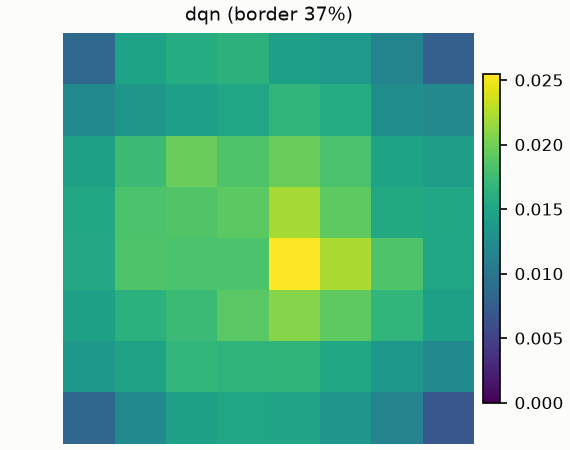

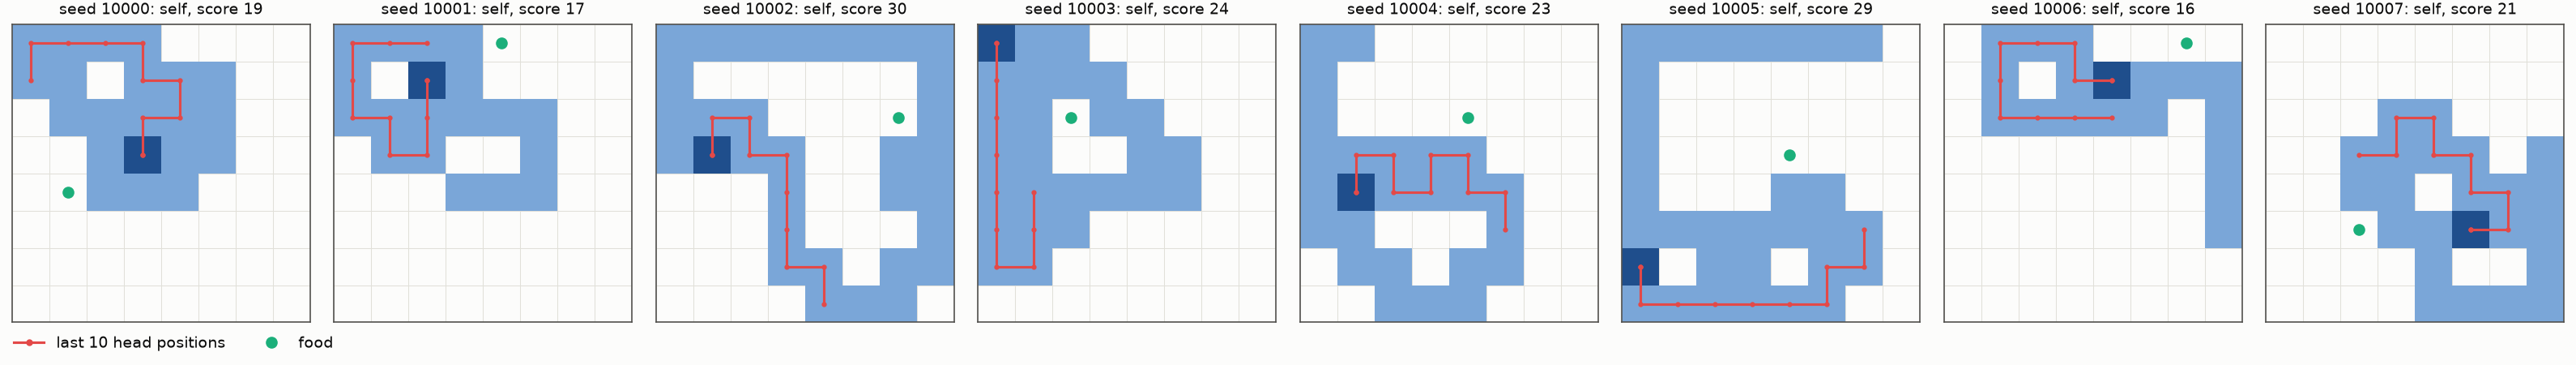

{
  "n_episodes": 100,
  "score_mean": 22.13,
  "steps_mean": 203.23,
  "length_mean": 25.13,
  "frac_wall": 0.0,
  "frac_self": 1.0,
  "frac_starve": 0.0,
  "frac_win": 0.0,
  "frac_truncated": 0.0,
  "frac_cut": 0.0,
  "tail_without_food_mean": 10.18,
  "loop_fraction": 0.0,
  "loop_steps_mean": 0.92,
  "shaping_reward_mean": 0.0,
  "border_fraction_mean": 0.3626421806178402,
  "q_max_mean": 8.440579130040605,
  "player": "dqn",
  "env": {
    "W": 8,
    "action_mode": "relative",
    "starve_limit": null,
    "obs": {
      "kind": "B",
      "age_plane": true,
      "heading_planes": true
    },
    "reward": {
      "variant": "R0",
      "food": 1.0,
      "death": -1.0,
      "step_penalty": 0.01,
      "gamma": 0.99,
      "closer": 0.01,
      "farther": 0.0
    }
  },
  "seed": 10000,
  "max_steps": null,
  "git": "47bec9e+dirty",
  "hacking_cases": [],
  "checkpoint": 512000,
  "source": "runs/dqn_B8_W8_gamma099/0"
}


In [24]:
# Behaviour analysis of one run: 100 greedy episodes, heat-map, loop statistics and recordings of the longest loops
RUN_DIR = "runs/dqn_B8_W8_gamma099/0"   # any run directory with model.pt
OUT_DIR = "runs/behaviour/notebook"

if os.path.exists(os.path.join(RUN_DIR, "model.pt")):
    !{sys.executable} -m snake_rl.analysis.behaviour --player {RUN_DIR} --checkpoint final --device {DEVICE} --out-dir {OUT_DIR}
    display(Image(filename=os.path.join(OUT_DIR, "heatmap.png")))
    display(Image(filename=os.path.join(OUT_DIR, "last_steps.png")))
    with open(os.path.join(OUT_DIR, "summary.json"), encoding="utf-8") as f:
        print(json.dumps(json.load(f), indent=2)[:2000])
else:
    print("no weights at", RUN_DIR, "- the logs zip carries none; see the note above")